In [1]:
!pip install torchtext==0.4.0 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 1.9 MB/s eta 0:00:00


In [2]:
from torchtext import data, datasets
import torch
# For tokenization
TEXT = data.Field(tokenize='spacy',
                  tokenizer_language='en_core_web_sm',
                  include_lengths = True)
# For multi-class classification labels
LABEL = data.LabelField()
# Load the TREC dataset
# train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)
train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)

downloading train_5500.label


train_5500.label: 100%|██████████| 336k/336k [00:00<00:00, 1.16MB/s]


downloading TREC_10.label


TREC_10.label: 100%|██████████| 23.4k/23.4k [00:00<00:00, 332kB/s]


In [3]:
TEXT.build_vocab(train_data,
                max_size=25000,
                vectors="glove.6B.100d",
                # min_freq=3,
                unk_init=torch.Tensor.normal_)
LABEL.build_vocab(train_data)

.vector_cache/glove.6B.zip: 862MB [02:39, 5.40MB/s]                           
100%|█████████▉| 399999/400000 [00:19<00:00, 20877.72it/s]


In [7]:
!pip install transformers -q

Using device: cuda
Loading BERT tokenizer...
Preparing data...
Train: 4634, Valid: 818, Test: 500
Loading BERT model...


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Starting BERT training...


Evaluating: 100%|██████████| 52/52 [00:05<00:00,  9.13it/s]


Epoch 1/5 | Train Loss: 0.648 Acc: 79.43% | Valid Loss: 0.213 Acc: 93.77%
  Best model saved.


Evaluating: 100%|██████████| 52/52 [00:05<00:00,  9.16it/s]


... (5 outputs left out)

Evaluating: 100%|██████████| 52/52 [00:05<00:00,  9.08it/s]


Epoch 5/5 | Train Loss: 0.028 Acc: 99.37% | Valid Loss: 0.173 Acc: 95.60%
  Best model saved.

Best BERT model loaded for final evaluation.


Evaluating: 100%|██████████| 32/32 [00:03<00:00,  9.24it/s]



---- Loading best BERT model for final test evaluation ----

Final BERT Test Loss: 0.160 | Final BERT Test Accuracy: 96.80%


Classification report:
              precision    recall  f1-score   support

        ENTY       0.99      0.87      0.93        94
         HUM       0.98      0.98      0.98        65
        DESC       0.94      1.00      0.97       138
         NUM       0.97      1.00      0.99       113
         LOC       0.98      0.99      0.98        81
        ABBR       1.00      0.78      0.88         9

    accuracy                           0.97       500
   macro avg       0.98      0.94      0.95       500
weighted avg       0.97      0.97      0.97       500



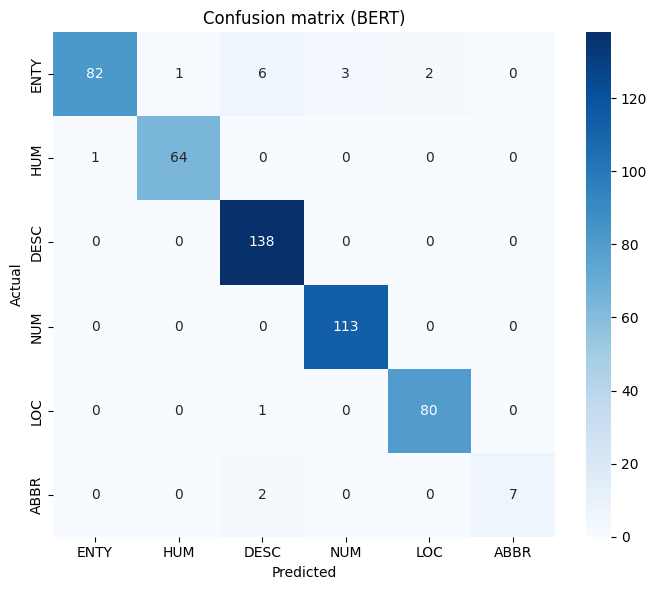

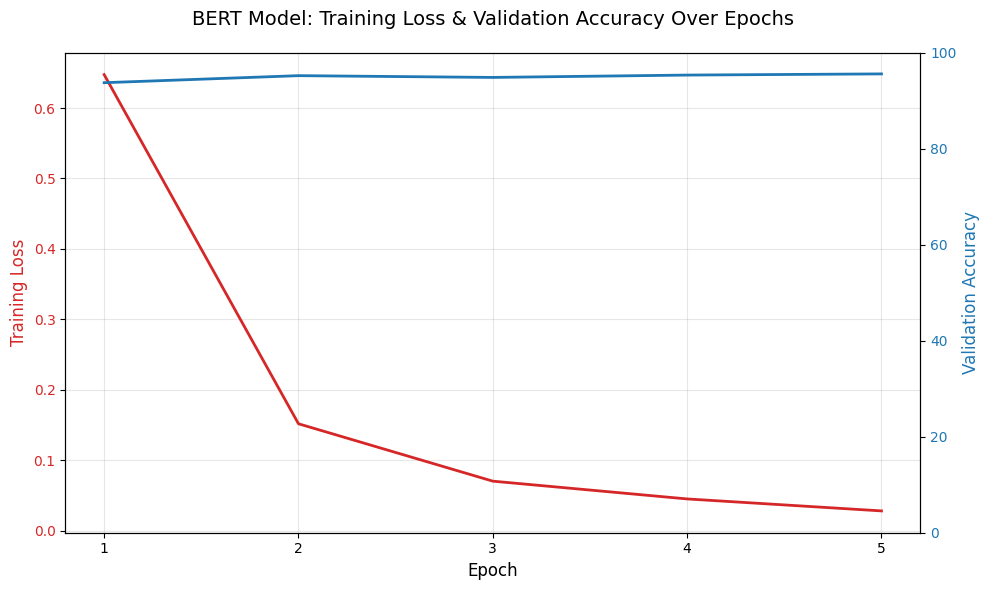

✅ BERT plot saved as 'bert_training_curves.png'
PART 3(c) COMPLETE!


In [17]:
# ============================================================================
# PART 3(c): BERT MODEL - COMPLETE WORKING CODE
# ============================================================================

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import random

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

BERT_MODEL = 'bert-base-uncased'
MAX_LENGTH = 128
BATCH_SIZE = 16
N_EPOCHS = 4
LEARNING_RATE = 2e-5

train_data, valid_data = train_data.split(split_ratio=0.85, random_state=random.seed(42))

print(f"Loading BERT tokenizer...")
tokenizer = BertTokenizer.from_pretrained(BERT_MODEL)

print("Preparing data...")

def get_texts_labels(dataset):
    texts = []
    labels = []
    for example in dataset:
        text = ' '.join(example.text)
        texts.append(text)
        labels.append(example.label)
    return texts, labels

train_texts, train_labels = get_texts_labels(train_data)
valid_texts, valid_labels = get_texts_labels(valid_data)
test_texts, test_labels = get_texts_labels(test_data)

label_to_idx = {label: idx for idx, label in enumerate(LABEL.vocab.itos)}
train_labels = [label_to_idx[label] if isinstance(label, str) else label for label in train_labels]
valid_labels = [label_to_idx[label] if isinstance(label, str) else label for label in valid_labels]
test_labels = [label_to_idx[label] if isinstance(label, str) else label for label in test_labels]

print(f"Train: {len(train_texts)}, Valid: {len(valid_texts)}, Test: {len(test_texts)}")

class BERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'label': torch.tensor(label, dtype=torch.long)
        }

train_dataset = BERTDataset(train_texts, train_labels, tokenizer, MAX_LENGTH)
valid_dataset = BERTDataset(valid_texts, valid_labels, tokenizer, MAX_LENGTH)
test_dataset = BERTDataset(test_texts, test_labels, tokenizer, MAX_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print(f"Loading BERT model...")
model = BertForSequenceClassification.from_pretrained(BERT_MODEL, num_labels=len(LABEL.vocab))
model = model.to(device)

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)
total_steps = len(train_loader) * N_EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

def train_epoch(model, data_loader, optimizer, scheduler, device):
    model.train()
    losses = []
    correct = 0
    total = 0

    for batch in tqdm(data_loader, desc="Training"):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        optimizer.step()
        scheduler.step()

        losses.append(loss.item())

        _, predicted = torch.max(logits.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = np.mean(losses)
    accuracy = correct / total
    return avg_loss, accuracy

def evaluate_model(model, data_loader, device):
    model.eval()
    losses = []
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(data_loader, desc="Evaluating"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            logits = outputs.logits

            losses.append(loss.item())

            _, predicted = torch.max(logits.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())


    avg_loss = np.mean(losses)
    accuracy = correct / total
    return avg_loss, accuracy, all_preds, all_labels

# Training loop
print("\nStarting BERT training...")
bert_train_losses, bert_valid_accs = [], []
best_valid_acc = 0.0

for epoch in range(N_EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, device)
    valid_loss, valid_acc, _, _ = evaluate_model(model, valid_loader, device)

    bert_train_losses.append(train_loss)
    bert_valid_accs.append(valid_acc * 100)

    print(f'Epoch {epoch+1}/{N_EPOCHS} | Train Loss: {train_loss:.3f} Acc: {train_acc*100:.2f}% | Valid Loss: {valid_loss:.3f} Acc: {valid_acc*100:.2f}%')

    if valid_acc > best_valid_acc:
        best_valid_acc = valid_acc
        torch.save(model.state_dict(), 'bert_model.pt')
        print("  Best model saved.")

# Load best model for evaluation
model.load_state_dict(torch.load('bert_model.pt'))
print("\nBest BERT model loaded for final evaluation.")

test_loss, test_acc, test_preds, test_labels = evaluate_model(model, test_loader, device)

print(f'\n{"="*80}')
print(f'---- Loading best BERT model for final test evaluation ----')
print(f'\nFinal BERT Test Loss: {test_loss:.3f} | Final BERT Test Accuracy: {test_acc*100:.2f}%')
print(f'{"="*80}\n')

# Classification report and Confusion Matrix (similar to Part 2)
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

label_names = LABEL.vocab.itos
print("\nClassification report:")
print(classification_report(test_labels, test_preds, target_names=label_names))

# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.title('Confusion matrix (BERT)')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Plot Training Loss and Validation Accuracy
epochs = list(range(1, N_EPOCHS + 1))

fig, ax1 = plt.subplots(figsize=(10, 6))

color_loss = 'tab:red'
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Training Loss', color=color_loss, fontsize=12)
ax1.plot(epochs, bert_train_losses, color=color_loss, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_loss)
ax1.set_xticks(epochs)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color_acc = 'tab:blue'
ax2.set_ylabel('Validation Accuracy', color=color_acc, fontsize=12)
ax2.plot(epochs, bert_valid_accs, color=color_acc, linewidth=2)
ax2.tick_params(axis='y', labelcolor=color_acc)
ax2.set_ylim([0, 100]) # Assuming accuracy is in percentage

plt.title('BERT Model: Training Loss & Validation Accuracy Over Epochs', fontsize=14, pad=20)
fig.tight_layout()
plt.savefig('bert_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ BERT plot saved as 'bert_training_curves.png'")
print("="*80)
print("PART 3(c) COMPLETE!")
print("="*80)